In [1]:
print("Customer Segmentation Project")

Customer Segmentation Project


In [2]:
import pandas as pd 

In [3]:
df = pd.read_csv("../dataset/Mall_Customers.csv")

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.shape

(200, 5)

In [6]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

In [9]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


<Axes: >

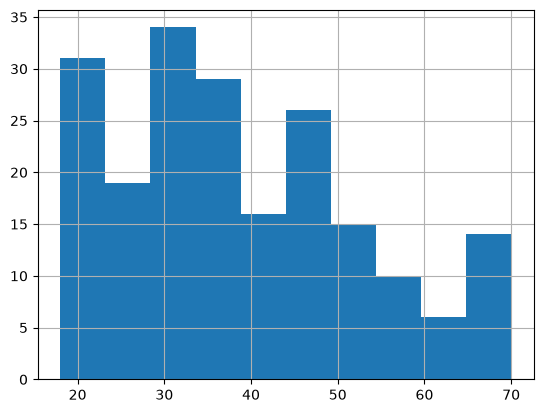

In [10]:
df["Age"].hist()

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

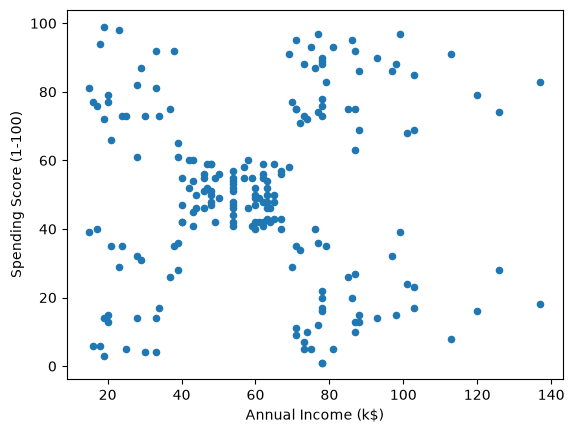

In [11]:
df.plot.scatter(
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

In [12]:
X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
scaler = StandardScaler()

In [15]:
X_scaled = scaler.fit_transform(X)

In [16]:
X_scaled[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

In [17]:
from sklearn.cluster import KMeans

print("KMeans is working in my notebook!")

KMeans is working in my notebook!


In [18]:
import pandas as pd

df = pd.read_csv("../dataset/Mall_Customers.csv")

print(df.shape)
df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [19]:
X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [20]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(200, 3)


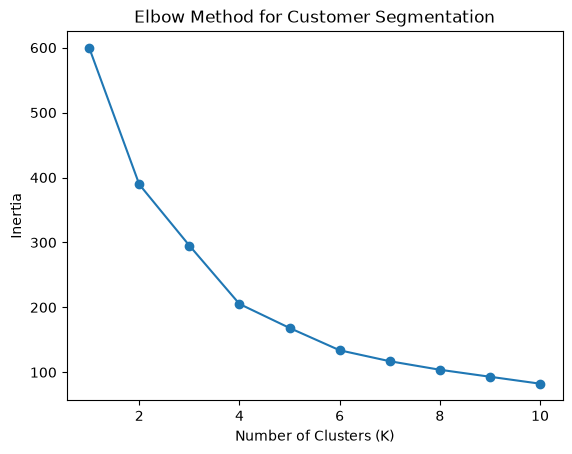

In [21]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia_values = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.show()

In [22]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans.fit(X_scaled)

print("K-Means model fitted successfully!")

K-Means model fitted successfully!


In [23]:
df["Cluster"] = kmeans.labels_

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


In [24]:
cluster_summary = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,53.98,47.71,39.97
1,32.88,86.10,81.53
2,25.44,40.00,60.30
3,39.37,86.50,19.58


In [25]:
df["Cluster"].value_counts().sort_index()

Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

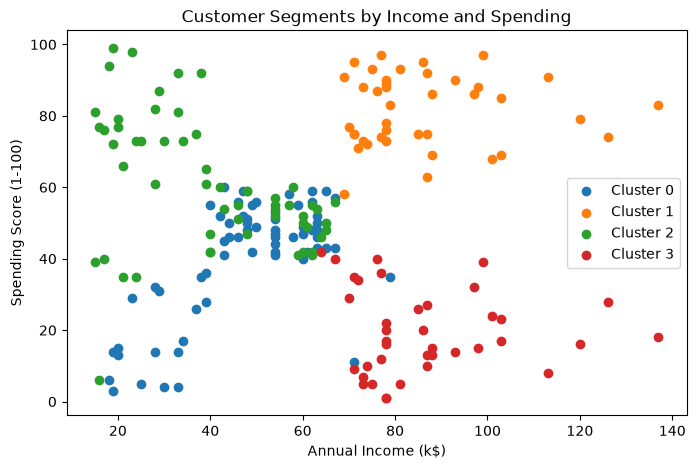

In [26]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments by Income and Spending")
plt.legend()
plt.show()

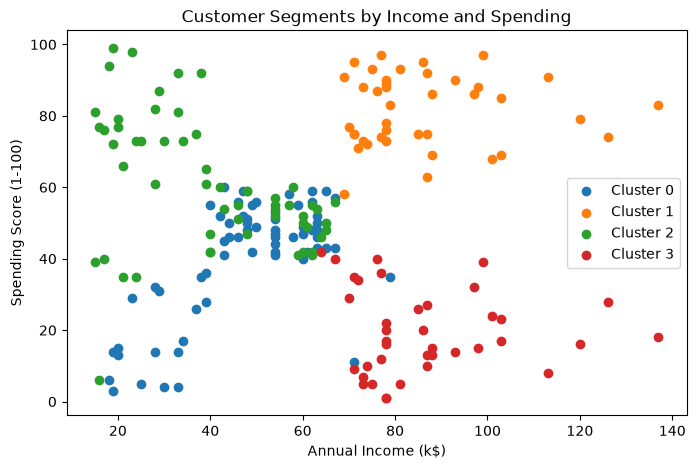

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments by Income and Spending")
plt.legend()
plt.show()

In [28]:
plt.savefig(
    "../visualizations/customer_segments_income_spending.png",
    dpi=300,
    bbox_inches="tight"
)


<Figure size 640x480 with 0 Axes>

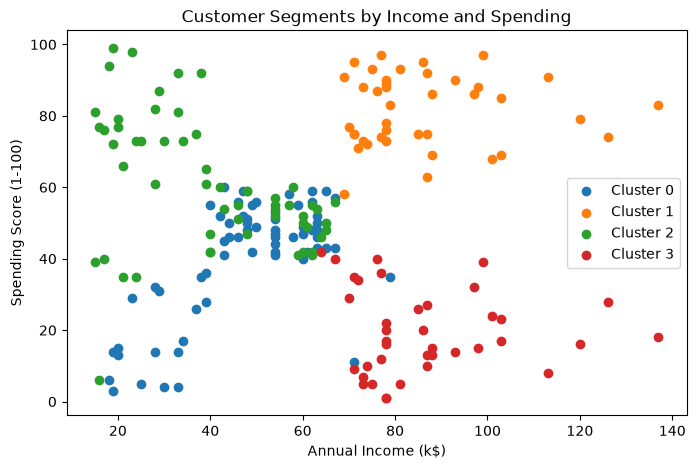

In [29]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments by Income and Spending")
plt.legend()

plt.savefig(
    "../visualizations/customer_segments_income_spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

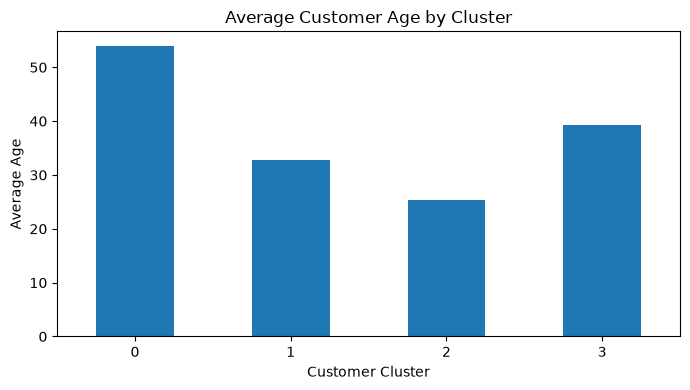

In [30]:
cluster_age = df.groupby("Cluster")["Age"].mean()

cluster_age.plot(kind="bar", figsize=(7, 4))

plt.xlabel("Customer Cluster")
plt.ylabel("Average Age")
plt.title("Average Customer Age by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

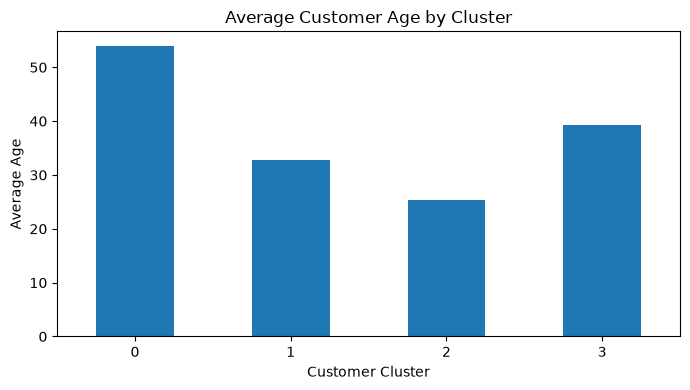

In [31]:
cluster_age = df.groupby("Cluster")["Age"].mean()

plt.figure(figsize=(7, 4))
cluster_age.plot(kind="bar")

plt.xlabel("Customer Cluster")
plt.ylabel("Average Age")
plt.title("Average Customer Age by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/average_customer_age_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

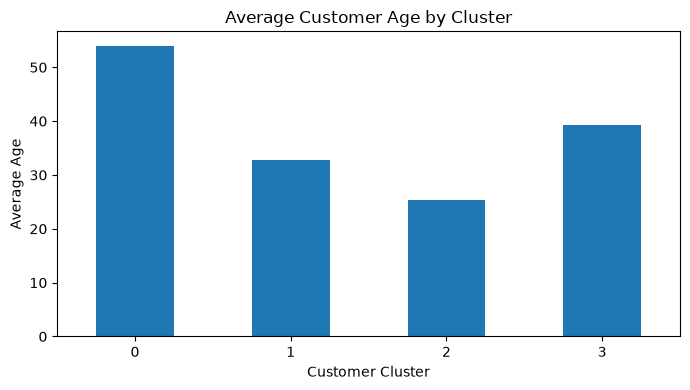

In [32]:
cluster_age = df.groupby("Cluster")["Age"].mean()

plt.figure(figsize=(7, 4))
cluster_age.plot(kind="bar")

plt.xlabel("Customer Cluster")
plt.ylabel("Average Age")
plt.title("Average Customer Age by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/average_customer_age_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

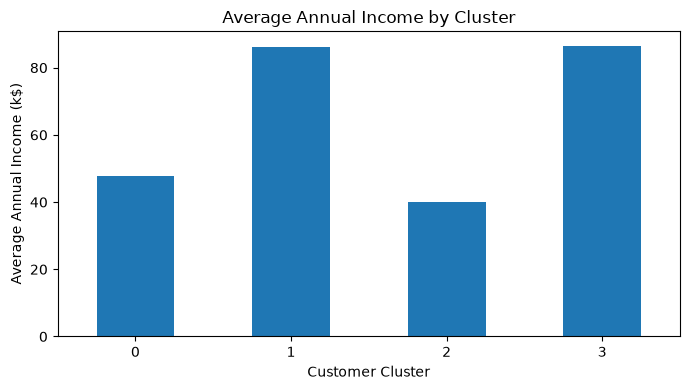

In [33]:
cluster_income = df.groupby("Cluster")["Annual Income (k$)"].mean()

plt.figure(figsize=(7, 4))
cluster_income.plot(kind="bar")

plt.xlabel("Customer Cluster")
plt.ylabel("Average Annual Income (k$)")
plt.title("Average Annual Income by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/average_income_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

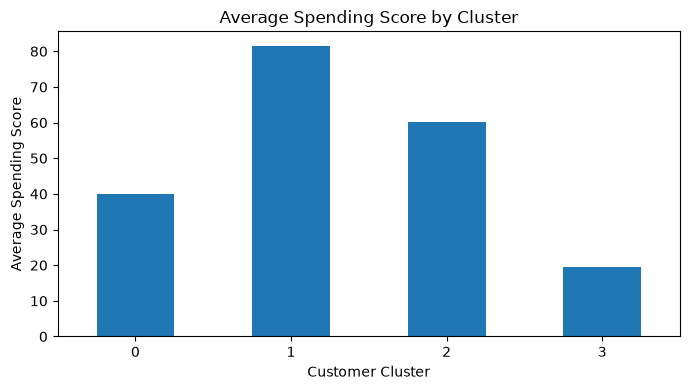

In [34]:
cluster_spending = df.groupby("Cluster")["Spending Score (1-100)"].mean()

plt.figure(figsize=(7, 4))
cluster_spending.plot(kind="bar")

plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending Score")
plt.title("Average Spending Score by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/average_spending_score_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
df.groupby('Cluster').mean(numeric_only=True).sort_values(by='Age')

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
2,53.438596,25.438596,40.000000,60.298246
1,161.025000,32.875000,86.100000,81.525000
3,160.552632,39.368421,86.500000,19.578947
0,69.415385,53.984615,47.707692,39.969231


## Key Findings

1. The Mall Customers dataset contains 200 customer records.
2. The Elbow Method suggested using 4 clusters for customer segmentation.
3. K-Means grouped the customers into four clusters containing 65, 40, 57, and 38 customers, respectively.
4. Cluster 0 contains the oldest customers on average, at approximately 54 years.
5. Cluster 1 has a high average annual income and a high average spending score.
6. Cluster 2 contains the youngest customers on average, at approximately 25 years.
7. Cluster 3 has a high average annual income but a low average spending score.

## Conclusion

K-Means clustering was used to segment customers based on age, annual income, and spending score. The analysis identified four groups with different customer characteristics. These segments can help a business better understand customer behaviour and plan more targeted marketing strategies.